# 14 — DBSCAN

> Clusters as crowded regions separated by empty space — any shape, any number, and an honest label for the points that belong nowhere.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. DBSCAN on generated data
5. Where k-means fails and DBSCAN does not
6. Clustering Canadian weather stations
7. References

## 1. The problem

K-means (lesson 12) and hierarchical clustering (lesson 13) both share a
weakness: **every point must belong to some cluster.** A lone weather station
in the Arctic, a single mistyped record, a customer unlike any other — each is
forced into the nearest group, pulling that group's centre toward it.

K-means has a second weakness: it builds clusters around centroids, so it can
only draw round, convex shapes. A cluster shaped like a crescent or a ring is
split wrongly no matter how many restarts it gets.

DBSCAN — *Density-Based Spatial Clustering of Applications with Noise* —
answers both:

- **Input:** rows of features, with no labels
- **Output:** a cluster number for each row, **or `-1` for noise**
- **A good answer** finds dense regions of any shape, and refuses to assign the
  points that sit in empty space.

## 2. Intuition

A cluster is a crowd. Draw a circle of radius $\varepsilon$ around a point and
count how many points fall inside:

- **Core point** — at least `min_samples` points in its circle (itself
  included). It sits in the middle of a crowd.
- **Border point** — not crowded enough to be a core point, but inside the
  circle of a core point. It is on the edge of a crowd.
- **Noise** — neither. It belongs to no crowd at all.

A cluster is then grown by chaining: start from a core point, add everything in
its circle, and keep expanding from every core point reached. Because the
chain can bend in any direction, the cluster can take any shape. And because
noise points are never reached, they are left out rather than forced in.

Two things DBSCAN does **not** need: the number of clusters, which falls out of
the data, and a starting position, so the result is the same on every run.

## 3. The mathematics

Let $N_\varepsilon(p) = \{\, q : d(p, q) \le \varepsilon \,\}$ be the
$\varepsilon$-neighbourhood of a point $p$. Then:

- $p$ is a **core point** if $\lvert N_\varepsilon(p) \rvert \ge \text{min\_samples}$.
- $q$ is **directly density-reachable** from $p$ if $p$ is a core point and
  $q \in N_\varepsilon(p)$.
- $q$ is **density-reachable** from $p$ if there is a chain
  $p = p_1, p_2, \dots, p_m = q$ in which each $p_{i+1}$ is directly
  density-reachable from $p_i$.
- $p$ and $q$ are **density-connected** if some point $o$ has both of them
  density-reachable from it.

A **cluster** is a maximal set of density-connected points. Every point that
belongs to no cluster is **noise**.

**Choosing $\varepsilon$.** The two parameters interact: `min_samples` says how
many neighbours make a crowd, and $\varepsilon$ says how close they must be. A
standard way to choose $\varepsilon$ is the **k-distance plot**: for every
point, measure the distance to its $k$-th nearest neighbour with
$k = $ `min_samples`, sort those distances and plot them. Points inside
clusters have small values; noise points have large ones. Setting
$\varepsilon$ near where the curve bends upward separates the two.

**Distance must mean something.** Like k-means, DBSCAN depends entirely on the
distance $d$. Features on different scales need standardising; and for
latitude and longitude, straight-line distance on the raw degrees is wrong,
because a degree of longitude shrinks toward the poles. The **haversine**
distance measures the true distance over the Earth's surface instead:

$$
d = 2R \arcsin \sqrt{ \sin^2\!\frac{\Delta\varphi}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\!\frac{\Delta\lambda}{2} }
$$

with latitudes $\varphi$ and longitudes $\lambda$ in radians and
$R \approx 6371$ km. scikit-learn's haversine metric returns the angle
$d / R$, so an $\varepsilon$ of 100 km is passed as $100 / 6371$.

## 4. DBSCAN on generated data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

### Data generation

The same kind of data as the previous two lessons: points around chosen centres.
The helper below generates them and standardises both coordinates.
`random_state=0` makes every run produce the same points.

In [2]:
def createDataPoints(centroidLocation, numSamples, clusterDeviation):
    # Create random data and store in feature matrix X and response vector y.
    X, y = make_blobs(n_samples=numSamples, centers=centroidLocation,
                      cluster_std=clusterDeviation, random_state=0)

    # Standardize features by removing the mean and scaling to unit variance
    X = StandardScaler().fit_transform(X)
    return X, y

1,500 points around three centres — $(4, 3)$, $(2, -1)$ and $(-1, 4)$ — with
standard deviation 0.5.

In [3]:
X, y = createDataPoints([[4,3], [2,-1], [-1,4]] , 1500, 0.5)

### Modeling

`eps` is the radius $\varepsilon$ and `min_samples` the size of a crowd. The
data is standardised, so `eps=0.3` means 0.3 standard deviations.

In [4]:
epsilon = 0.3
minimumSamples = 7
db = DBSCAN(eps=epsilon, min_samples=minimumSamples).fit(X)
labels = db.labels_
labels

array([0, 1, 0, ..., 2, 0, 2], dtype=int64)

### Core, border and noise points

`core_sample_indices_` lists the core points. A boolean mask marks them, so each
point can be identified as one of the three kinds from section 2.

In [5]:
# First, create an array of booleans using the labels from db.
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

print("Core points:  ", core_samples_mask.sum())
print("Border points:", ((labels != -1) & ~core_samples_mask).sum())
print("Noise points: ", (labels == -1).sum())

Core points:   1498
Border points: 2
Noise points:  0


In [6]:
# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_clusters_

3

In [7]:
# Remove repetition in labels by turning it into a set.
unique_labels = set(labels)
unique_labels

{0, 1, 2}

### Data visualization

Core points are drawn large, border points small, and noise — if any — in black.

In [8]:
# Create colors for the clusters.
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

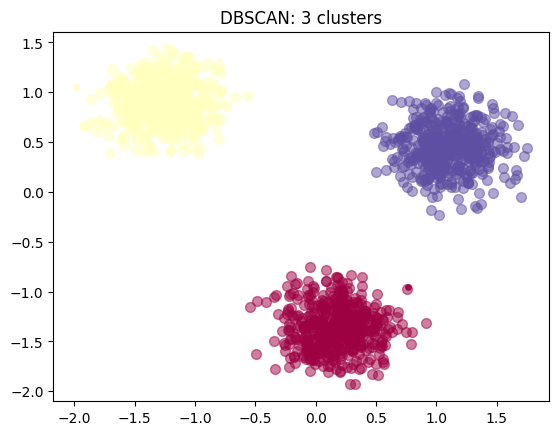

In [9]:
# Plot the points with colors
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = 'k'

    class_member_mask = (labels == k)

    # Plot the core points
    xy = X[class_member_mask & core_samples_mask]
    plt.scatter(xy[:, 0], xy[:, 1], s=50, color=col, marker='o', alpha=0.5)

    # Plot the border points and noise
    xy = X[class_member_mask & ~core_samples_mask]
    plt.scatter(xy[:, 0], xy[:, 1], s=15, color=col, marker='o', alpha=0.9)

plt.title(f'DBSCAN: {n_clusters_} clusters')
plt.show()

DBSCAN finds all three groups, and 1,498 of the 1,500 points are core points:
these blobs are dense and well separated, so almost every point sits in the
middle of a crowd and none is left over as noise.

### The same data with k-means

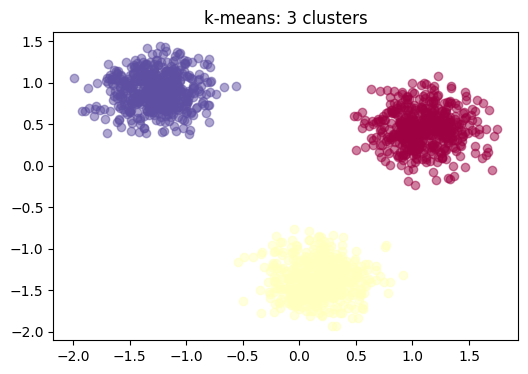

In [10]:
n_k = 3
k_means3 = KMeans(init = "k-means++", n_clusters = n_k, n_init = 12, random_state = 0)
k_means3.fit(X)
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
for k, col in zip(range(n_k), colors):
    my_members = (k_means3.labels_ == k)
    ax.scatter(X[my_members, 0], X[my_members, 1], color=col, marker='o', alpha=0.5)
ax.set_title('k-means: 3 clusters')
plt.show()

An identical result. On round, well-separated groups the two methods agree —
this is exactly the kind of data k-means was designed for. To see what DBSCAN
adds, the clusters need a shape k-means cannot draw.

## 5. Where k-means fails and DBSCAN does not

`make_moons` generates two interleaving half-circles: two clearly separate
groups, but neither of them round.

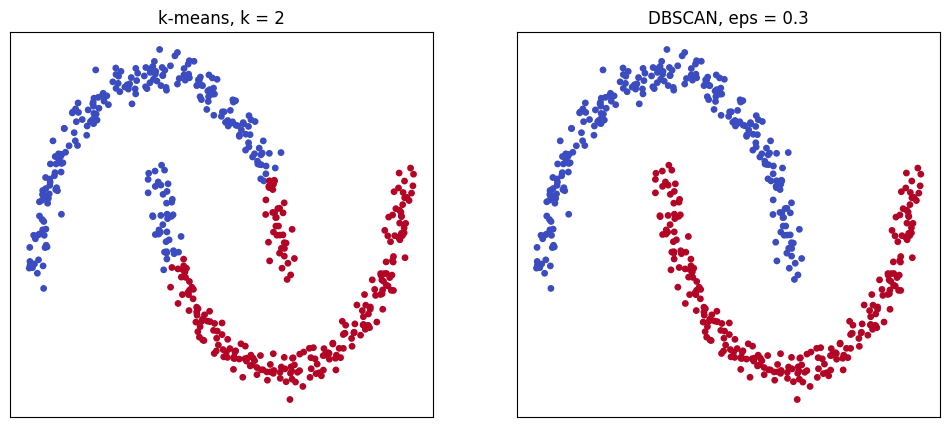

In [11]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.05, random_state=0)
X_moons = StandardScaler().fit_transform(X_moons)

db_moons = DBSCAN(eps=0.3, min_samples=5).fit(X_moons)
km_moons = KMeans(n_clusters=2, n_init=12, random_state=0).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in [(axes[0], km_moons, 'k-means, k = 2'),
                         (axes[1], db_moons, 'DBSCAN, eps = 0.3')]:
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=model.labels_, cmap='coolwarm', s=15)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.savefig('figures/moons.png', dpi=150, bbox_inches='tight')
plt.show()

**k-means cuts straight across both moons.** It places two centroids and assigns
each point to the nearer one, so the boundary between its clusters is always a
straight line — the perpendicular bisector of the two centroids. No straight
line separates two interlocking crescents.

**DBSCAN follows each crescent.** It never looks for a centre; it only chains
crowded points together. Each moon is one continuous dense region, so each
becomes one cluster, whatever its shape.

This is the case DBSCAN exists for. It is not a better k-means — on the blobs
above they were identical — but it answers a different question: *where are
the crowds?* rather than *where are the centres?*

## 6. Clustering Canadian weather stations

### The dataset

Environment Canada publishes monthly summaries from its weather stations. This
file holds one month of them, from 2014. The original lab describes it as July
2015, but the temperatures say otherwise: mean temperatures run from −36 °C to
+10 °C, so this is a winter month.

| Column | Meaning |
|---|---|
| `Stn_Name` | Station name |
| `Lat`, `Long` | Latitude (north +) and longitude (west −), in degrees |
| `Prov` | Province or territory |
| `Tm` | Mean temperature (°C) |
| `Tx` | Highest maximum temperature in the month (°C) |
| `Tn` | Lowest minimum temperature in the month (°C) |
| `D` | Difference of `Tm` from the 1981–2010 normal (°C) |
| `S`, `P` | Snowfall (cm) and total precipitation (mm) |
| `S_G` | Snow on the ground at the end of the month (cm) |
| `Pd` | Days with 1 mm of precipitation or more |
| `BS` | Bright sunshine (hours) |
| `HDD`, `CDD` | Heating and cooling degree days (below / above 18 °C) |
| `DwTm`, `DwTx`, … | Days without a valid reading for that measurement |
| `S%N`, `P%N`, `BS%` | Snowfall, precipitation and sunshine as % of normal |
| `Stn_No` | Climate station identifier |

In [12]:
pdf = pd.read_csv("data/weather-stations20140101-20141231.csv")
print("Shape:", pdf.shape)
pdf.head(5)

Shape: (1341, 25)


,Stn_Name,Lat,Long,Prov,Tm,DwTm,D,Tx,DwTx,Tn,...,DwP,P%N,S_G,Pd,BS,DwBS,BS%,HDD,CDD,Stn_No
0,CHEMAINUS,48.935,-123.742,BC,8.2,0.0,NaN,13.5,0.0,1.0,...,0.0,NaN,0.0,12.0,NaN,NaN,NaN,273.3,0.0,1011500
1,COWICHAN LAKE FORESTRY,48.824,-124.133,BC,7.0,0.0,3.0,15.0,0.0,-3.0,...,0.0,104.0,0.0,12.0,NaN,NaN,NaN,307.0,0.0,1012040
2,LAKE COWICHAN,48.829,-124.052,BC,6.8,13.0,2.8,16.0,9.0,-2.5,...,9.0,NaN,NaN,11.0,NaN,NaN,NaN,168.1,0.0,1012055
3,DISCOVERY ISLAND,48.425,-123.226,BC,NaN,NaN,NaN,12.5,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1012475
4,DUNCAN KELVIN CREEK,48.735,-123.728,BC,7.7,2.0,3.4,14.5,2.0,-1.0,...,2.0,NaN,NaN,11.0,NaN,NaN,NaN,267.7,0.0,1012573


### Cleaning

Stations with no mean temperature recorded are dropped.

In [13]:
pdf = pdf[pd.notnull(pdf["Tm"])]
pdf = pdf.reset_index(drop=True)
print("Shape:", pdf.shape)

Shape: (1256, 25)


### The stations on a map

`cartopy` draws the map: it projects latitude and longitude onto a flat Mercator
map and supplies coastlines, borders and land. The map is restricted to a box
around southern and central Canada, which removes the few stations outside it.

The drawing code is wrapped in two small functions, because the same map is
drawn three times below.

Stations on the map: 1189


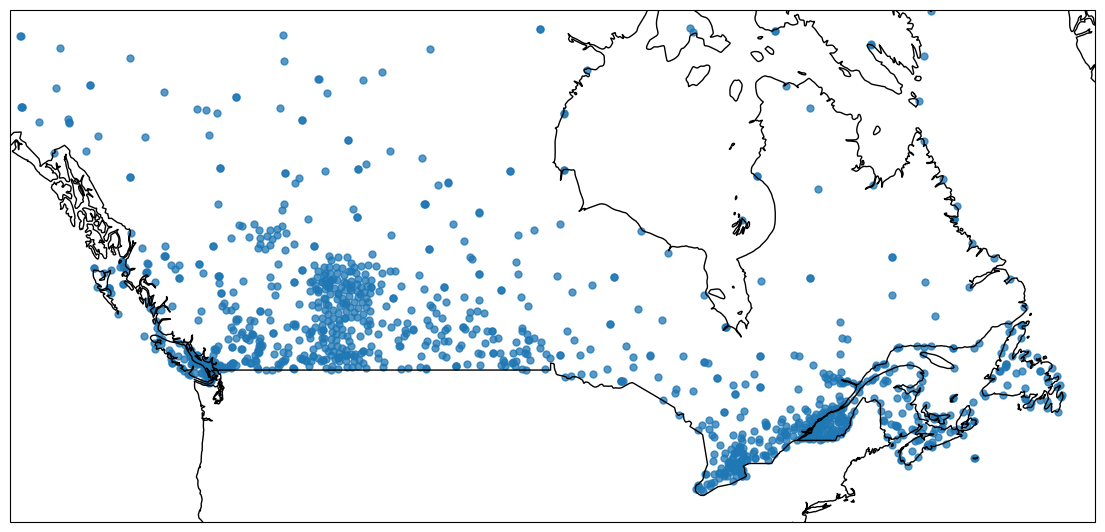

In [14]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plt.rcParams['figure.figsize'] = (14, 10)

llon, ulon = -140, -50
llat, ulat = 40, 65

pdf = pdf[
    (pdf['Long'] > llon) &
    (pdf['Long'] < ulon) &
    (pdf['Lat'] > llat) &
    (pdf['Lat'] < ulat)
].reset_index(drop=True)
print("Stations on the map:", len(pdf))


def draw_map():
    # Create map projection and set map boundaries
    ax = plt.axes(projection=ccrs.Mercator())
    ax.set_extent([llon, ulon, llat, ulat], crs=ccrs.PlateCarree())

    # Map features
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS)
    ax.add_feature(cfeature.LAND, facecolor='white', alpha=0.3)
    return ax


def plot_clusters(df, labels, title):
    ax = draw_map()
    # tab10 without its grey (index 7), so no cluster can be mistaken for noise
    tab10 = plt.get_cmap('tab10')(np.arange(10))
    colors = [c for i, c in enumerate(tab10) if i != 7] + ['black']

    for clust_number in sorted(set(labels)):
        # -1 = noise in DBSCAN, drawn small and grey
        is_noise = clust_number == -1
        c = [0.6, 0.6, 0.6] if is_noise else colors[clust_number % len(colors)]
        clust_set = df[labels == clust_number]

        ax.scatter(clust_set.Long, clust_set.Lat, color=c, marker='o',
                   s=8 if is_noise else 20, alpha=0.85,
                   transform=ccrs.PlateCarree())

        # Label each cluster at its average position
        if not is_noise:
            ax.text(clust_set.Long.mean(), clust_set.Lat.mean(), str(clust_number),
                    fontsize=22, color='red', transform=ccrs.PlateCarree())

    ax.set_title(title)
    return ax


ax = draw_map()
ax.scatter(pdf['Long'], pdf['Lat'], transform=ccrs.PlateCarree(),
           marker='o', s=25, alpha=0.75)
plt.show()

The stations are far from evenly spread. They crowd along the southern border —
southern British Columbia, the Prairie cities, the Quebec–Ontario corridor, the
Maritimes — and thin out quickly to the north.

### Clustering by location

Latitude and longitude are angles on a sphere, not coordinates on a flat page,
so the distance between stations is measured with the **haversine** metric from
section 3. It needs the angles in radians.

First, the k-distance plot: for every station, the distance to its 10th-nearest
neighbour, sorted.

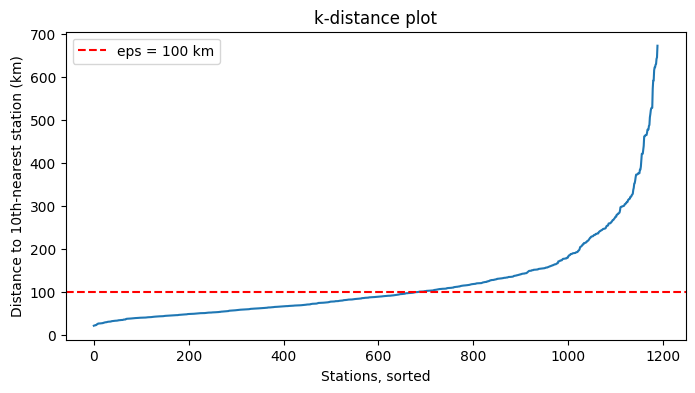

Median distance to the 10th-nearest station: 88 km


In [15]:
EARTH_RADIUS_KM = 6371
coords = np.radians(pdf[['Lat', 'Long']].values)

min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples, metric='haversine', algorithm='ball_tree')
distances, _ = nn.fit(coords).kneighbors(coords)
k_distance_km = np.sort(distances[:, -1]) * EARTH_RADIUS_KM

plt.figure(figsize=(8, 4))
plt.plot(k_distance_km)
plt.axhline(100, color='red', linestyle='--', label='eps = 100 km')
plt.xlabel('Stations, sorted')
plt.ylabel('Distance to 10th-nearest station (km)')
plt.title('k-distance plot')
plt.legend()
plt.show()

print("Median distance to the 10th-nearest station: %.0f km" % np.median(k_distance_km))

The curve rises slowly and then climbs steeply in its last fifth. Most stations
have ten neighbours within roughly 50–150 km; the steep tail is the scattered
northern and rural stations, hundreds of kilometres from their tenth neighbour.

There is no single sharp elbow here, which is common with real data. An
$\varepsilon$ of **100 km** sits on the gentle part of the curve, so it treats
the dense southern networks as clusters and the scattered stations as noise —
and, unlike a standardised unit, 100 km means something anyone can picture.

In [16]:
db_loc = DBSCAN(eps=100 / EARTH_RADIUS_KM, min_samples=min_samples,
                metric='haversine', algorithm='ball_tree').fit(coords)
pdf["Clus_Loc"] = db_loc.labels_

print("Clusters:", len(set(db_loc.labels_)) - (1 if -1 in db_loc.labels_ else 0))
print("Noise stations:", (db_loc.labels_ == -1).sum())

Clusters: 8
Noise stations: 347


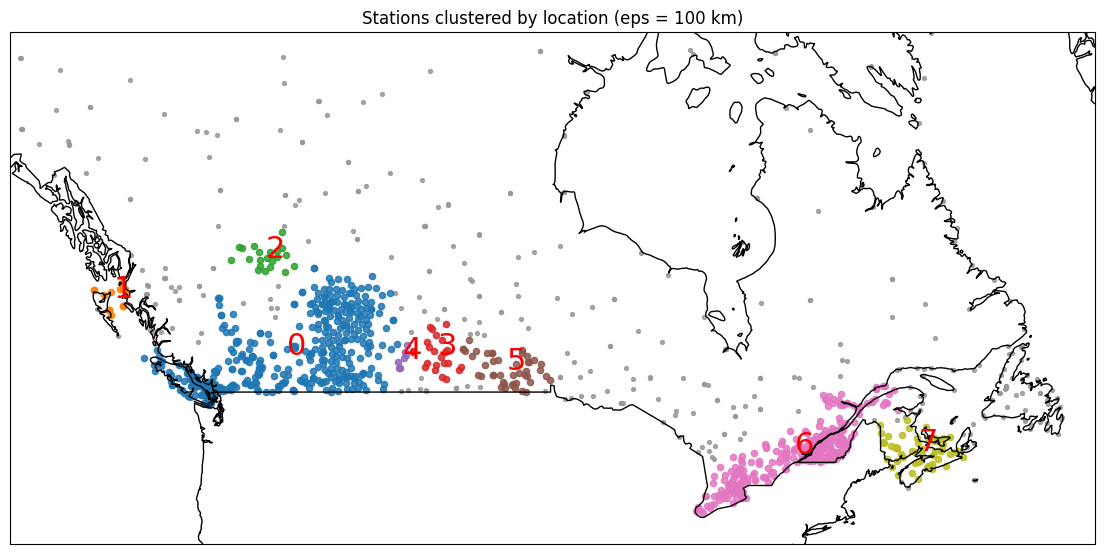

In [17]:
plot_clusters(pdf, pdf["Clus_Loc"], 'Stations clustered by location (eps = 100 km)')
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

A summary of each cluster — its size, average position, average temperature,
and the province most of its stations are in:

In [18]:
def summarise(df, column):
    return (df.groupby(column)
              .agg(stations=('Stn_Name', 'size'),
                   lat=('Lat', 'mean'),
                   long=('Long', 'mean'),
                   mean_temp=('Tm', 'mean'),
                   main_province=('Prov', lambda s: s.value_counts().index[0]))
              .round(1))

summarise(pdf, "Clus_Loc")

,stations,lat,long,mean_temp,main_province
Clus_Loc,,,,,
-1,347,53.2,-90.9,-16.7,ON
0,405,51.0,-117.0,-2.4,BC
1,16,53.9,-131.4,6.6,BC
2,21,55.8,-118.8,-9.6,AB
3,23,51.0,-104.5,-17.2,SK
4,7,50.8,-107.4,-13.0,SK
5,44,50.2,-98.8,-19.1,MB
6,272,45.5,-74.9,-16.0,QC
7,54,45.7,-64.6,-12.1,NS


The clusters are the dense station networks:

| Cluster | Stations | Region | Mean temp (°C) |
|---|---|---|---|
| 0 | 405 | Southern British Columbia and Alberta | −2.4 |
| 6 | 272 | The Quebec–Ontario corridor along the St Lawrence | −16.0 |
| 7 | 54 | The Maritimes | −12.1 |
| 5 | 44 | Southern Manitoba | −19.1 |
| 3 | 23 | Southern Saskatchewan | −17.2 |
| 2 | 21 | The Peace region of northern Alberta | −9.6 |
| 1 | 16 | Haida Gwaii and the north BC coast | +6.6 |
| 4 | 7 | South-western Saskatchewan | −13.0 |

**347 stations — 29% — are noise.** They are the stations without nine others
within 100 km, and they are scattered across the whole country rather than
confined to the far north: only 112 of them lie north of 55°. Every station in
Newfoundland and Labrador is noise, because the island's stations are spread
along a long coastline, and so are more than a third of Ontario's (59 of 164),
spread thinly across a very large province. k-means would have attached each of
them to some centre. DBSCAN says, correctly, that they do not form a crowd.

Cluster 0 is the one questionable result. It holds 198 stations in British
Columbia, 190 in Alberta and 17 in Saskatchewan — one unbroken chain from the
Pacific coast to the prairies, because the station networks are continuous
across the mountains, each station within 100 km of the next. That is DBSCAN working as
designed: it follows density, wherever the chain leads. But the coast and the
interior have very different winters, which location alone cannot see.

### Clustering by location and temperature

Adding the three temperature measurements — highest maximum, mean and lowest
minimum — lets the clustering separate places that are close together but
have different climates. Five features on different scales are standardised
first, so here latitude and longitude are treated as ordinary numbers rather
than with the haversine metric; the haversine distance has no way to combine
with temperatures.

Rows missing any of the five values are dropped, rather than filled with zeros
— a missing temperature is not 0 °C.

In [19]:
features_5d = ['Lat', 'Long', 'Tx', 'Tm', 'Tn']
pdf5 = pdf.dropna(subset=features_5d).reset_index(drop=True)
print("Stations with all five values:", len(pdf5))

X5 = StandardScaler().fit_transform(pdf5[features_5d])

db_5d = DBSCAN(eps=0.3, min_samples=10).fit(X5)
pdf5["Clus_5D"] = db_5d.labels_

print("Clusters:", len(set(db_5d.labels_)) - (1 if -1 in db_5d.labels_ else 0))
print("Noise stations:", (db_5d.labels_ == -1).sum())

Stations with all five values: 1188
Clusters: 10
Noise stations: 432


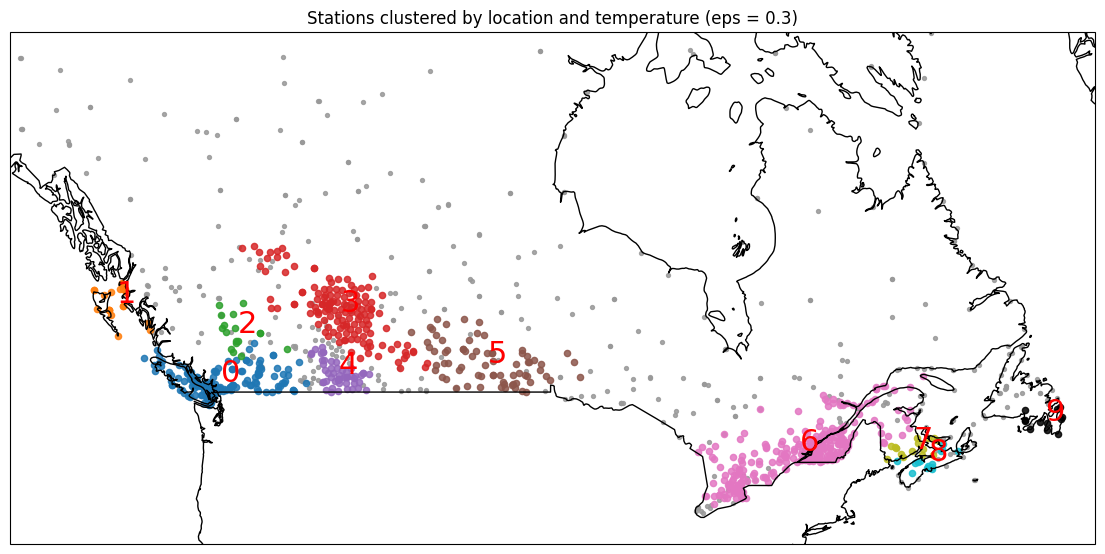

In [20]:
plot_clusters(pdf5, pdf5["Clus_5D"], 'Stations clustered by location and temperature (eps = 0.3)')
plt.savefig('figures/clusters_5d.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
summarise(pdf5, "Clus_5D")

,stations,lat,long,mean_temp,main_province
Clus_5D,,,,,
-1,432,52.4,-93.9,-14.9,BC
0,151,49.6,-122.5,6.2,BC
1,20,53.6,-131.1,6.8,BC
2,17,52.2,-121.1,-0.5,BC
3,144,53.2,-112.6,-11.4,AB
4,51,50.0,-112.8,-4.2,AB
5,72,50.6,-100.4,-18.7,MB
6,260,45.7,-74.5,-16.3,QC
7,15,45.8,-65.1,-13.6,NB


**Temperature splits British Columbia.** The single location cluster 0 now
divides by climate:

| Cluster | Stations | Region | Mean temp (°C) |
|---|---|---|---|
| 0 | 151 | The BC coast and the southern valleys | +6.2 |
| 1 | 20 | Haida Gwaii and the north coast | +6.8 |
| 2 | 17 | The central BC interior | −0.5 |
| 3 | 144 | Alberta | −11.4 |
| 4 | 51 | Southern Alberta, the chinook belt | −4.2 |

The coast, warmed by the Pacific, averages about 6 °C; a short distance inland,
behind the mountains, it is around freezing; most of Alberta is colder still.
Southern Alberta separates from the rest of the province as well — the warm
chinook winds that come down off the Rockies keep its winters milder. Location
alone saw one connected network. Location and temperature together see three
climates.

The east — Manitoba, the Quebec–Ontario corridor, New Brunswick, Nova Scotia
and Newfoundland — divides into its own clusters on the same principle.
Newfoundland is a telling case: by distance alone every one of its stations was
noise, but with temperature included, twelve of them are similar enough to form
a cluster.

**The cost is more noise.** Five dimensions spread the points out, so fewer have
nine neighbours within $\varepsilon$: 432 stations are noise here, against 347
by location alone. Adding features always makes crowds harder to find.

**$\varepsilon$ matters a great deal.** In five standardised dimensions, small
changes to `eps` change the result sharply — larger values quickly merge most
of the country into one cluster. Unlike 100 km, a value of 0.3 standard
deviations has no physical meaning to check it against, so this result should
be read as one reasonable view of the data rather than the answer.

## 7. References

- Dataset: Environment Canada monthly climate summaries
  (`weather-stations20140101-20141231.csv`), as supplied with the course.
- Course: Machine Learning with Python (Jadi), based on the IBM / Cognitive Class
  DBSCAN lab.
- Ester, M., Kriegel, H.-P., Sander, J. and Xu, X. (1996). *A Density-Based
  Algorithm for Discovering Clusters in Large Spatial Databases with Noise*.
  Proceedings of KDD-96, 226–231.
- Schubert, E., Sander, J., Ester, M., Kriegel, H.-P. and Xu, X. (2017).
  *DBSCAN Revisited, Revisited: Why and How You Should (Still) Use DBSCAN*.
  ACM Transactions on Database Systems 42(3).
- [scikit-learn: DBSCAN](https://scikit-learn.org/stable/modules/clustering.html#dbscan)
- [Cartopy documentation](https://scitools.org.uk/cartopy/docs/latest/)